In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [3]:
df = pd.read_csv("cleaned_customer_churn.csv")
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619.0,France,Female,42.0,2.0,0.00,1.0,1.0,1.0,101348.88,1
1,2,15647311,Hill,608.0,Spain,Female,41.0,1.0,83807.86,1.0,0.0,1.0,112542.58,0
2,3,15619304,Onio,502.0,France,Female,42.0,8.0,159660.80,3.0,1.0,0.0,113931.57,1
3,4,15701354,Boni,699.0,France,Female,39.0,1.0,0.00,2.0,0.0,0.0,93826.63,0
4,5,15737888,Mitchell,850.0,Spain,Female,43.0,2.0,125510.82,1.0,1.0,1.0,79084.10,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  float64
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  float64
 7   Tenure           10000 non-null  float64
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  float64
 10  HasCrCard        10000 non-null  float64
 11  IsActiveMember   10000 non-null  float64
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(8), int64(3), str(3)
memory usage: 1.2 MB


In [5]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.759882,38.665800,5.012134,77124.385017,1.523350,0.706700,0.519600,100185.103890,0.203700
std,2886.89568,7.193619e+04,95.974360,9.711289,2.882444,62026.049461,0.571238,0.455298,0.499641,57082.716373,0.402769
min,1.00000,1.556570e+07,387.000000,18.000000,-3.000000,0.000000,1.000000,0.000000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,585.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,52138.300000,0.000000
50%,5000.50000,1.569074e+07,650.665494,37.000000,5.000000,97338.190000,1.000000,1.000000,1.000000,100626.509183,0.000000
75%,7500.25000,1.575323e+07,717.000000,44.000000,7.000000,127209.612500,2.000000,1.000000,1.000000,148351.287500,0.000000
max,10000.00000,1.581569e+07,915.000000,62.000000,13.000000,318024.031250,3.500000,1.000000,1.000000,292670.768750,1.000000


In [6]:
df.shape

(10000, 14)

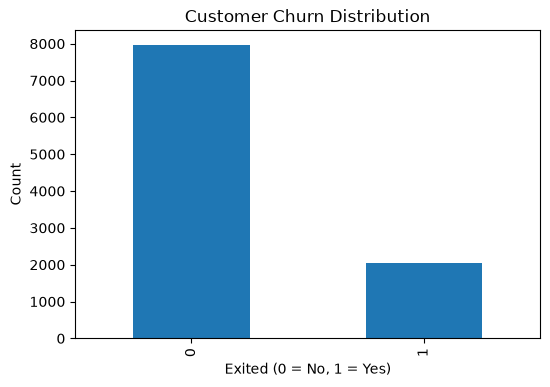

In [8]:
percentage = df['Exited'].value_counts(normalize=True) * 100

plt.figure(figsize=(6, 4))
df['Exited'].value_counts().plot(kind='bar')
plt.xlabel('Exited (0 = No, 1 = Yes)')
plt.ylabel('Count')
plt.title('Customer Churn Distribution')
plt.show()

## Univariate analysis

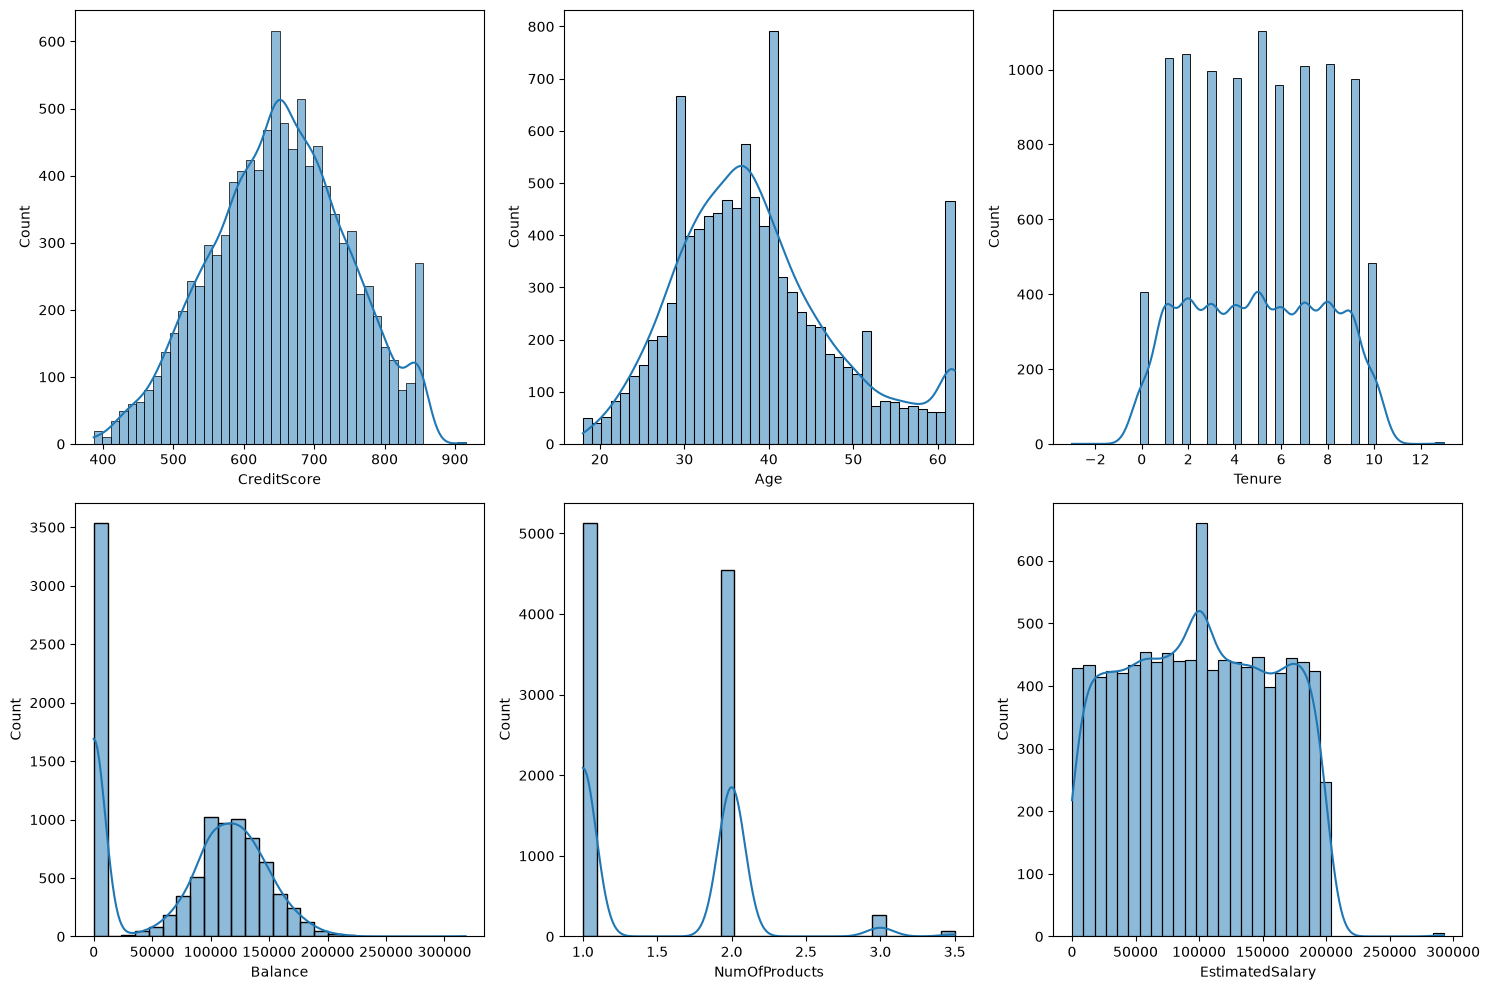

In [9]:
numeric_features = ['CreditScore', 'Age', 'Tenure', 'Balance',
                    'NumOfProducts', 'EstimatedSalary']

plt.figure(figsize=(15, 10))
for i in range(0, len(numeric_features)):
    plt.subplot(2, 3, i+1)
    sns.histplot(x=df[numeric_features[i]], kde=True)
    plt.xlabel(numeric_features[i])
    plt.tight_layout()

## Bivariate analysis

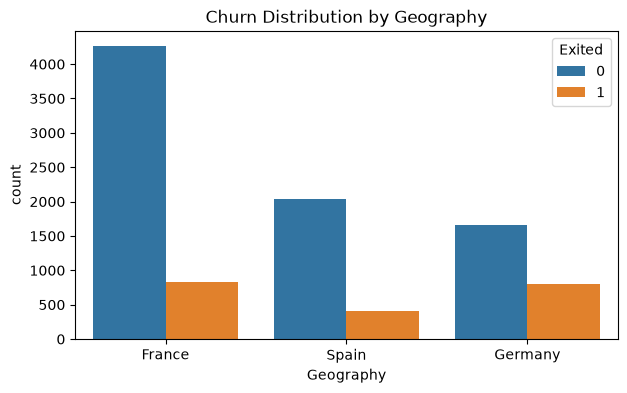

In [10]:
plt.figure(figsize=(7, 4))
sns.countplot(x='Geography', hue='Exited', data=df)
plt.title('Churn Distribution by Geography')
plt.show()

In [15]:
print("Churn rate by Geography:")
print(df.groupby('Geography')['Exited'].mean() * 100)

Churn rate by Geography:
Geography
France     16.231600
Germany    32.494929
Spain      16.762295
Name: Exited, dtype: float64


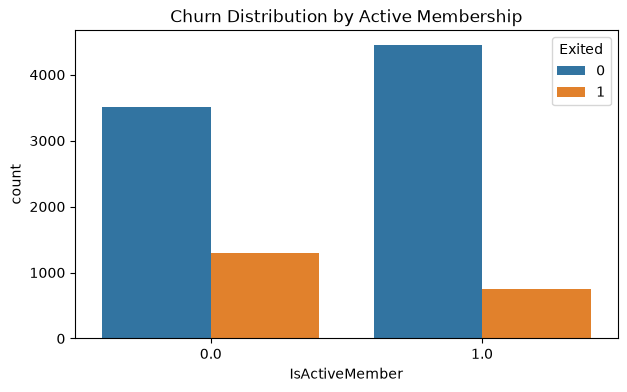

In [11]:
plt.figure(figsize=(7, 4))
sns.countplot(x='IsActiveMember', hue='Exited', data=df)
plt.title('Churn Distribution by Active Membership')
plt.show()

In [14]:
print("Churn rate by Active Membership:")
print(df.groupby('IsActiveMember')['Exited'].mean() * 100)

Churn rate by Active Membership:
IsActiveMember
0.0    26.831807
1.0    14.395689
Name: Exited, dtype: float64


array([[<Axes: title={'center': 'RowNumber'}>,
        <Axes: title={'center': 'CustomerId'}>,
        <Axes: title={'center': 'CreditScore'}>],
       [<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'Tenure'}>,
        <Axes: title={'center': 'Balance'}>],
       [<Axes: title={'center': 'NumOfProducts'}>,
        <Axes: title={'center': 'HasCrCard'}>,
        <Axes: title={'center': 'IsActiveMember'}>],
       [<Axes: title={'center': 'EstimatedSalary'}>,
        <Axes: title={'center': 'Exited'}>, <Axes: >]], dtype=object)

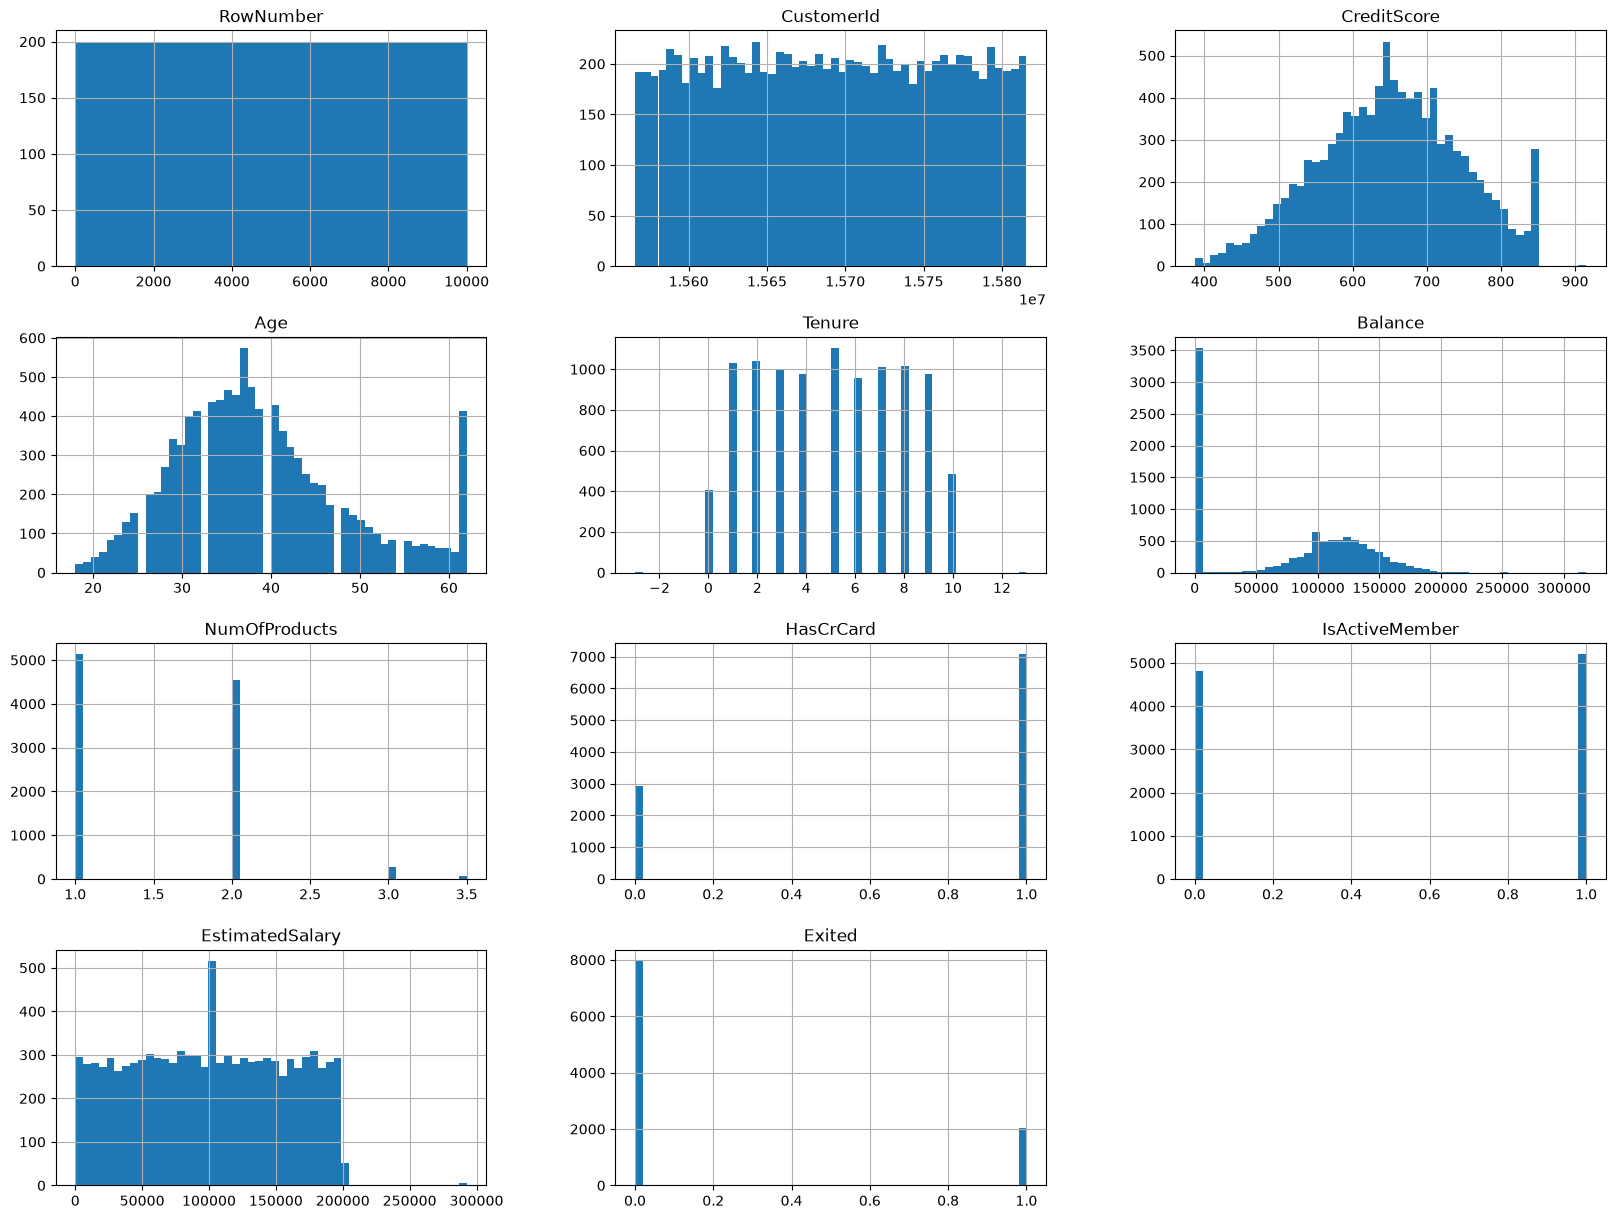

In [21]:
df.hist(bins=50, figsize=(20, 15))

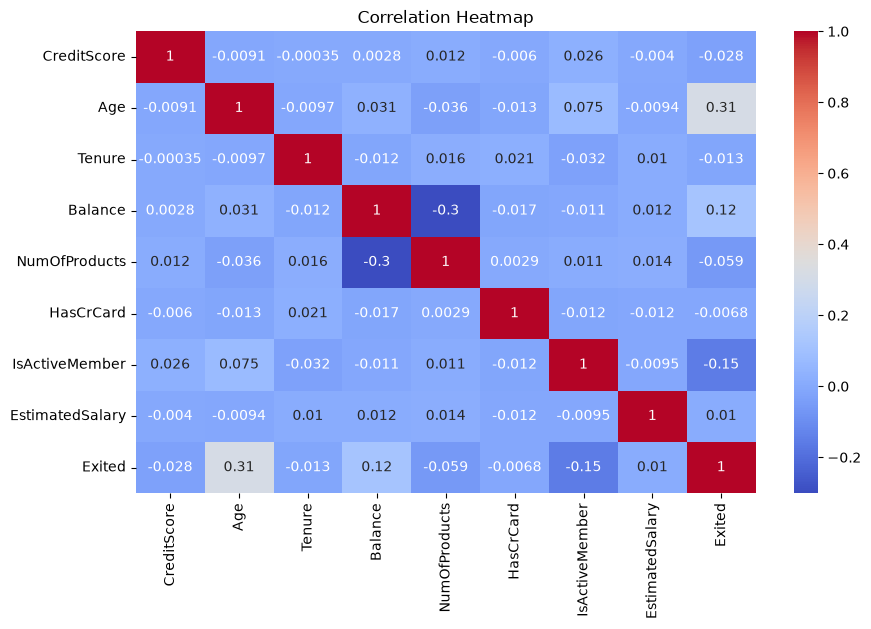

In [19]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.select_dtypes(include='number').drop(
    columns=['RowNumber', 'CustomerId'], errors='ignore'
).corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()